# Histogram

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Bins one numeric variable into intervals and draws a bar for the count in each. It is the standard way to see a distribution's shape, centre, spread, skew and gaps.

## When to use

- Show the shape of one numeric variable (normal, skewed, bimodal)
- Find outliers, gaps and impossible values during data cleaning
- Communicate a distribution to a general audience

## Avoid when

- There are fewer than ~30 values (use a strip or dot plot)
- Comparing more than two or three groups (overlapping bars become unreadable)

## Alternatives

- KDE density curve
- Box plot
- ECDF

## Design tips

- Try several bin widths; the shape can change with binning
- Leave no gaps between bars, because the x-axis is continuous
- Mark the mean or median with a reference line

## Example

Delivery times (minutes) for 2,000 food orders, right-skewed (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(5)
df = pd.DataFrame({"minutes": rng.gamma(4.5, 7, 2000) + 8})
df["minutes"].describe().round(1)

count    2000.0
mean       40.2
std        14.8
min        12.6
25%        29.4
50%        38.1
75%        48.7
max       108.2
Name: minutes, dtype: float64

### Plot

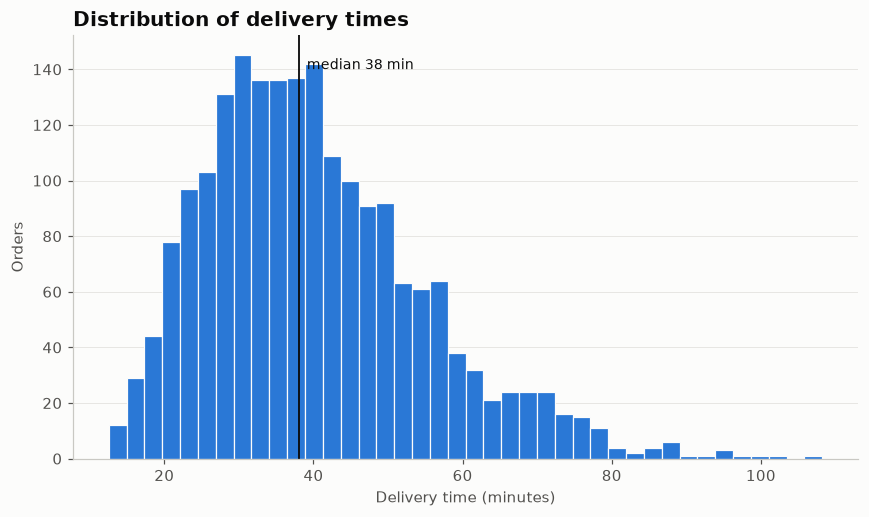

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(df["minutes"], bins=40, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.8)
med = df["minutes"].median()
ax.axvline(med, color="#0b0b0b", linewidth=1.2)
ax.text(med + 1, ax.get_ylim()[1] * 0.92, f"median {med:.0f} min", fontsize=9)
ax.set_xlabel("Delivery time (minutes)")
ax.set_ylabel("Orders")
ax.set_title("Distribution of delivery times")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

The middle half of orders arrive in about 30–50 minutes, with a median of 38. The long right tail means a minority of orders are much slower, which pulls the mean above the median.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.histogram(df, x="minutes", nbins=40, color_discrete_sequence=PALETTE,
                   labels={"minutes": "Delivery time (minutes)"}, title="Distribution of delivery times")
fig.add_vline(x=df["minutes"].median(), line_color="#0b0b0b", line_width=1.2,
              annotation_text=f"median {df['minutes'].median():.0f} min")
fig.update_traces(marker_line_color="#fcfcfb", marker_line_width=0.8)
fig.update_layout(yaxis_title="Orders", bargap=0)
fig.show()

### altair

In [5]:
import altair as alt
bars = alt.Chart(df).mark_bar(color=PALETTE[0]).encode(
    x=alt.X("minutes:Q", bin=alt.Bin(maxbins=40), title="Delivery time (minutes)"),
    y=alt.Y("count():Q", title="Orders"), tooltip=["count()"])
median = alt.Chart(df).mark_rule(color="#0b0b0b").encode(x="median(minutes):Q")
chart = (bars + median).properties(title="Distribution of delivery times", width=520, height=300)
chart

alt.LayerChart(...)

---
Standalone script: [`histogram.py`](histogram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)